In [ ]:
# Імпортування бібліотек
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics
import warnings
warnings.filterwarnings('ignore')
from google.colab import files
files.upload()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import pandas as pd
df2 = pd.read_csv('test_sample.csv', engine='python')
df2

,platform,account_id,id,created_time,text_original,text_additional,likes_count,shares_count,comments_count,views_count
0,Instagram,59141296785,C_00PPctR-o,2024-09-12 17:20:36.000000 +00:00,NaN,NaN,222.0,NaN,34.0,NaN
1,Instagram,60554087008,C_00W8KttVv,2024-09-12 17:21:27.000000 +00:00,C’è un gruppo sulla parola di Dio sulla mia ho...,NaN,391.0,NaN,37.0,NaN
2,Instagram,62605500679,C_026U_t3We,2024-09-12 17:43:38.000000 +00:00,𝐒𝐮𝐥 𝐦𝐢𝐨 𝐩𝐫𝐨𝐟𝐢𝐥𝐨 𝐜‘𝐞̀ 𝐮𝐧 𝐠𝐫𝐮𝐩𝐩𝐨 𝐝𝐢 𝐬𝐭𝐮𝐝𝐢𝐨 𝐬𝐮𝐥𝐥𝐚...,NaN,9.0,NaN,3.0,NaN
3,Instagram,58741537308,C_05B3hCYQn,2024-09-12 18:02:08.000000 +00:00,#Monza\n#Padova\n#Lecce\n#Latina\n#paroladelsi...,NaN,78.0,NaN,15.0,NaN
4,Instagram,58741537308,C_0BfOLiqRS,2024-09-12 09:57:22.000000 +00:00,#Monza\n#Padova\n#Lecce\n#Latina\n#paroladelsi...,NaN,129.0,NaN,16.0,NaN
...,...,...,...,...,...,...,...,...,...,...
10520,YouTube,UCXZUJg9kVm180MmCfQ4O4Fg,2ZrdyqdjST4,2024-10-10 15:16:59.000000 +00:00,"💞💞Будь ласка, не йдіть, не даруючи їм трохи лю...",NaN,2165.0,NaN,89.0,18613.0
10521,YouTube,UCXZUJg9kVm180MmCfQ4O4Fg,rzcLR-bjtrM,2024-09-30 03:30:33.000000 +00:00,"100% прочитають його, але лише 1% відповість: ...",NaN,53.0,NaN,8.0,1007.0
10522,YouTube,UCXZUJg9kVm180MmCfQ4O4Fg,jBIvuk6sr2I,2024-09-29 15:45:01.000000 +00:00,"Я дякую тим, хто привітав.Тільки ті, хто любит...",NaN,1271.0,NaN,28.0,22564.0
10523,YouTube,UCXZUJg9kVm180MmCfQ4O4Fg,qBVRIlPta04,2024-09-29 09:30:27.000000 +00:00,Нехай Бог благословить її і пошле теплі побажа...,NaN,302.0,NaN,7.0,3697.0


In [ ]:
# Видалення стовпців
df2 = df2.drop(columns=['text_additional', 'text_original', 'id', 'account_id'])

# Перевіримо результат
print(df2.head())

    platform                       created_time  likes_count  shares_count  \
0  Instagram  2024-09-12 17:20:36.000000 +00:00        222.0           NaN   
1  Instagram  2024-09-12 17:21:27.000000 +00:00        391.0           NaN   
2  Instagram  2024-09-12 17:43:38.000000 +00:00          9.0           NaN   
3  Instagram  2024-09-12 18:02:08.000000 +00:00         78.0           NaN   
4  Instagram  2024-09-12 09:57:22.000000 +00:00        129.0           NaN   

   comments_count  views_count  
0            34.0          NaN  
1            37.0          NaN  
2             3.0          NaN  
3            15.0          NaN  
4            16.0          NaN  


In [ ]:
# Перетворюємо created_time на datetime (якщо дані не у datetime-форматі)
df2['created_time'] = pd.to_datetime(df2['created_time'], errors='coerce')

# Додаємо нову колонку hour, витягуючи годину з created_time
df2['hour'] = df2['created_time'].dt.hour

# Перевіряємо результат
print(df2[['created_time', 'hour']].head())
df2 = df2.drop(columns=['created_time'])
df2

               created_time  hour
0 2024-09-12 17:20:36+00:00  17.0
1 2024-09-12 17:21:27+00:00  17.0
2 2024-09-12 17:43:38+00:00  17.0
3 2024-09-12 18:02:08+00:00  18.0
4 2024-09-12 09:57:22+00:00   9.0


,platform,likes_count,shares_count,comments_count,views_count,hour
0,Instagram,222.0,NaN,34.0,NaN,17.0
1,Instagram,391.0,NaN,37.0,NaN,17.0
2,Instagram,9.0,NaN,3.0,NaN,17.0
3,Instagram,78.0,NaN,15.0,NaN,18.0
4,Instagram,129.0,NaN,16.0,NaN,9.0
...,...,...,...,...,...,...
10520,YouTube,2165.0,NaN,89.0,18613.0,15.0
10521,YouTube,53.0,NaN,8.0,1007.0,3.0
10522,YouTube,1271.0,NaN,28.0,22564.0,15.0
10523,YouTube,302.0,NaN,7.0,3697.0,9.0


In [ ]:
print(df2['platform'].value_counts())

platform
Instagram                                                                2500
YouTube                                                                  2500
Facebook                                                                 2500
TikTok                                                                   2500
#preghiere                                                                 26
                                                                         ... 
#basilicadisuperga                                                          1
#BasilicadiSantaMariaaPugliano #gesù #preghire                              1
#BasilicadiSanFrancesco                                                     1
#Chiesa                                                                     1
Unisciti al gruppo Whatsapp sulla mia home page per dirti la risposta       1
Name: count, Length: 79, dtype: int64


In [ ]:
# Список допустимих платформ
valid_platforms = ["Instagram", "TikTok", "Facebook", "YouTube"]

# Фільтрація DataFrame, залишаємо лише рядки з потрібними значеннями у колонці 'platform'
df2 = df2[df2['platform'].isin(valid_platforms)]

# Перевіряємо унікальні значення після фільтрації
print(df2['platform'].unique())

['Instagram' 'TikTok' 'Facebook' 'YouTube']


In [ ]:
# Підрахунок кількості рядків для кожного унікального значення у колонці 'platform'
platform_counts = df2['platform'].value_counts()

# Виведення результату
print("Кількість рядків для кожної платформи:")
print(platform_counts)


Кількість рядків для кожної платформи:
platform
Instagram    2500
TikTok       2500
Facebook     2500
YouTube      2500
Name: count, dtype: int64


In [ ]:
# Проходимо по кожній групі (по кожній платформі)
for platform, group in df2.groupby('platform'):
    missing_counts = group.isna().sum()
    print(f"Платформа: {platform}")
    print(missing_counts.to_frame(name='К-сть пропущених значень'))
    print("-" * 40)

Платформа: Facebook
                К-сть пропущених значень
platform                               0
likes_count                            0
shares_count                           0
comments_count                         0
views_count                         1879
hour                                   0
----------------------------------------
Платформа: Instagram
                К-сть пропущених значень
platform                               0
likes_count                           49
shares_count                        2500
comments_count                        74
views_count                         2500
hour                                   0
----------------------------------------
Платформа: TikTok
                К-сть пропущених значень
platform                               0
likes_count                            0
shares_count                           0
comments_count                         0
views_count                            0
hour                                   

In [ ]:
# Обчислення середнього значення likes_count для платформи Instagram (ігноруючи NaN)
instagram_mean_likes = df2.loc[df2['platform'] == 'Instagram', 'likes_count'].mean()

# Заповнення тільки для рядків, де платформа Instagram
df2.loc[(df2['platform'] == 'Instagram') & (df2['likes_count'].isna()), 'likes_count'] = instagram_mean_likes

# Перевірка результату
print(df2[df2['platform'] == 'Instagram']['likes_count'])

0        222.0
1        391.0
2          9.0
3         78.0
4        129.0
         ...  
3020     303.0
3021    1209.0
3022    7081.0
3023     544.0
3024     639.0
Name: likes_count, Length: 2500, dtype: float64


In [ ]:
# Проходимо по кожній групі (по кожній платформі)
for platform, group in df2.groupby('platform'):
    missing_counts = group.isna().sum()
    print(f"Платформа: {platform}")
    print(missing_counts.to_frame(name='К-сть пропущених значень'))
    print("-" * 40)

Платформа: Facebook
                К-сть пропущених значень
platform                               0
likes_count                            0
shares_count                           0
comments_count                         0
views_count                         1879
hour                                   0
----------------------------------------
Платформа: Instagram
                К-сть пропущених значень
platform                               0
likes_count                            0
shares_count                        2500
comments_count                        74
views_count                         2500
hour                                   0
----------------------------------------
Платформа: TikTok
                К-сть пропущених значень
platform                               0
likes_count                            0
shares_count                           0
comments_count                         0
views_count                            0
hour                                   

In [ ]:
# Список змінних, де потрібно замінити NaN на середнє значення платформи
columns_to_fill = ['views_count', 'shares_count', 'comments_count']

for col in columns_to_fill:
    df2[col] = df2.groupby('platform')[col].transform(lambda x: x.fillna(x.mean()))


In [ ]:
df2 = df2[~df2['platform'].isin(['Instagram', 'YouTube'])]

In [ ]:
# Проходимо по кожній групі (по кожній платформі)
for platform, group in df2.groupby('platform'):
    missing_counts = group.isna().sum()
    print(f"Платформа: {platform}")
    print(missing_counts.to_frame(name='К-сть пропущених значень'))
    print("-" * 40)

Платформа: Facebook
                К-сть пропущених значень
platform                               0
likes_count                            0
shares_count                           0
comments_count                         0
views_count                            0
hour                                   0
----------------------------------------
Платформа: TikTok
                К-сть пропущених значень
platform                               0
likes_count                            0
shares_count                           0
comments_count                         0
views_count                            0
hour                                   0
----------------------------------------


<Axes: xlabel='likes_count', ylabel='Density'>

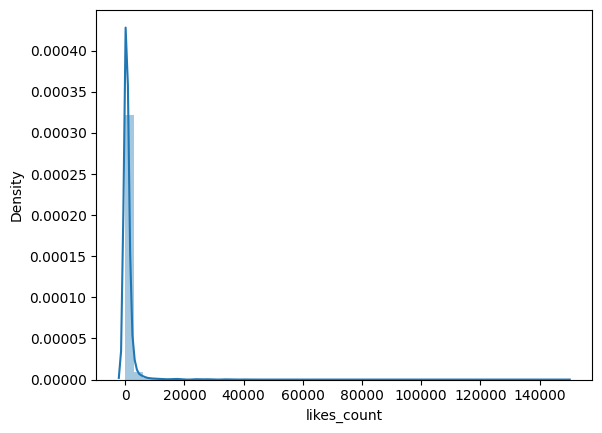

In [ ]:
import seaborn as sns
sns.distplot(df2['likes_count'])

In [ ]:
#Перевірка емпіричного правила
import numpy as np

# Вибираємо тільки числові стовпці
num_cols = ['likes_count', 'shares_count', 'comments_count', 'views_count', 'hour']

# Створимо словник для збереження результатів
empirical_results = {}

for col in num_cols:
    mean = df2[col].mean()
    std = df2[col].std()

    within_1_sigma = ((df2[col] >= mean - std) & (df2[col] <= mean + std)).mean() * 100
    within_2_sigma = ((df2[col] >= mean - 2*std) & (df2[col] <= mean + 2*std)).mean() * 100
    within_3_sigma = ((df2[col] >= mean - 3*std) & (df2[col] <= mean + 3*std)).mean() * 100

    empirical_results[col] = {
        'μ ± σ (68%)': within_1_sigma,
        'μ ± 2σ (95%)': within_2_sigma,
        'μ ± 3σ (99.7%)': within_3_sigma
    }

# Виведемо результати
import pandas as pd
empirical_df = pd.DataFrame(empirical_results).T
print(empirical_df)


                μ ± σ (68%)  μ ± 2σ (95%)  μ ± 3σ (99.7%)
likes_count           97.64         98.86           99.26
shares_count          99.22         99.54           99.74
comments_count        97.58         99.04           99.42
views_count           98.36         99.14           99.44
hour                  59.58         95.82          100.00


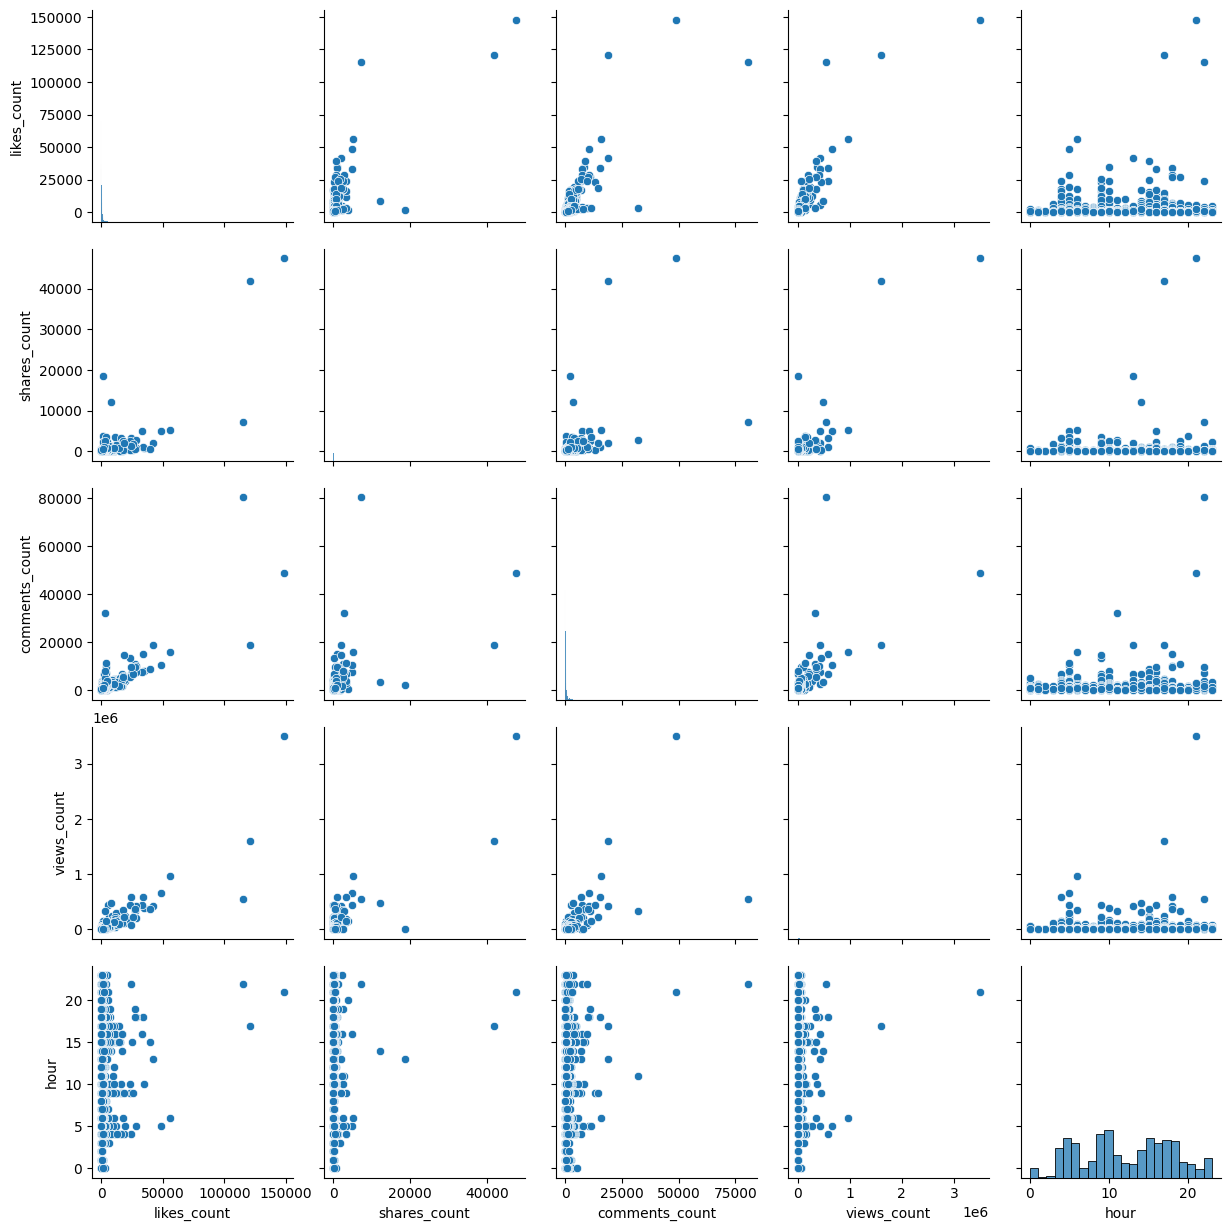

In [ ]:
sns.pairplot(df2)

In [ ]:
df2.describe()

,likes_count,shares_count,comments_count,views_count,hour
count,5000.000000,5000.000000,5000.00000,5.000000e+03,5000.000000
mean,928.450600,79.232000,412.49820,1.146742e+04,12.033400
std,3950.000657,979.564848,1666.37258,6.369930e+04,5.482764
min,0.000000,0.000000,0.00000,2.200000e+01,0.000000
25%,114.000000,3.000000,50.00000,3.172500e+03,8.000000
50%,339.500000,9.000000,150.00000,7.038887e+03,12.000000
75%,784.500000,43.000000,394.00000,7.038887e+03,17.000000
max,148000.000000,47500.000000,80415.00000,3.500000e+06,23.000000


Опис функції для побудови закону розподілу та QQplot - візуальна перевірка на "нормальність"

In [ ]:
#function to return plots for the feature
import scipy.stats as stats
import pylab
def normality(data,feature):
    plt.figure(figsize=(10,5))
    plt.subplot(1,2,1)
    sns.kdeplot(data[feature])
    plt.subplot(1,2,2)
    stats.probplot(data[feature],plot=pylab)
    plt.show()

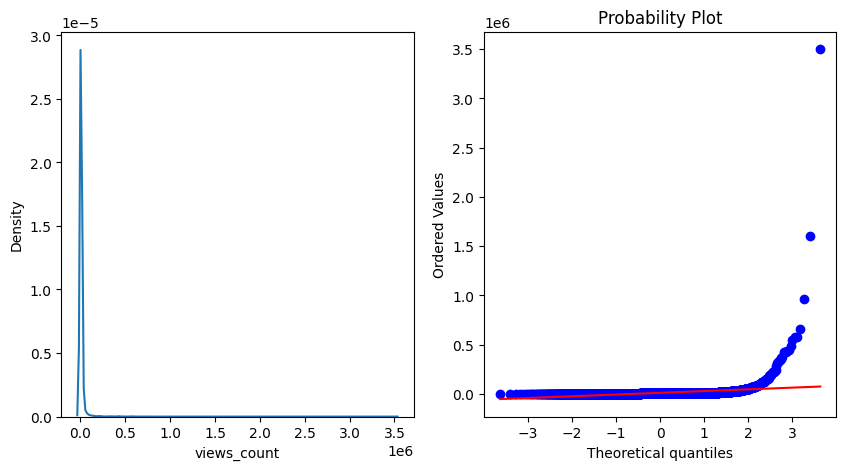

In [ ]:
normality(df2,'views_count')

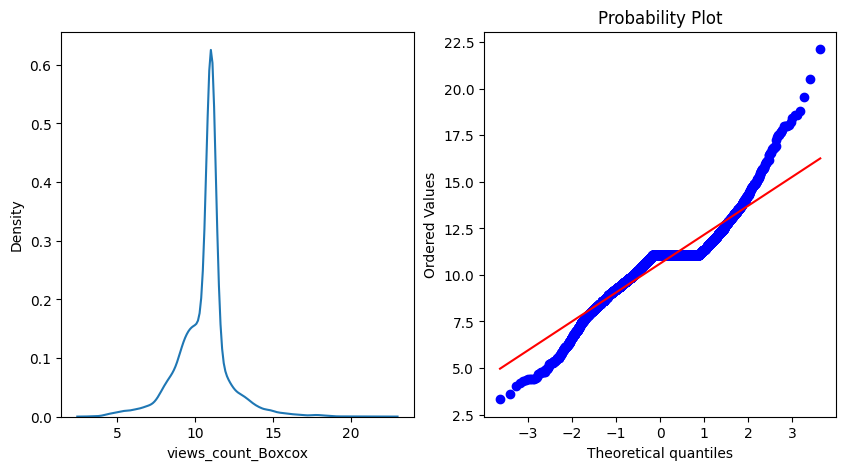

In [ ]:
df2['views_count_Boxcox'],parameters=stats.boxcox(df2['views_count'])
normality(df2,'views_count_Boxcox')

In [ ]:
#Оптимальне значення лямбда для перетворення Бокса Кокса
print(parameters)

0.0480737410807347


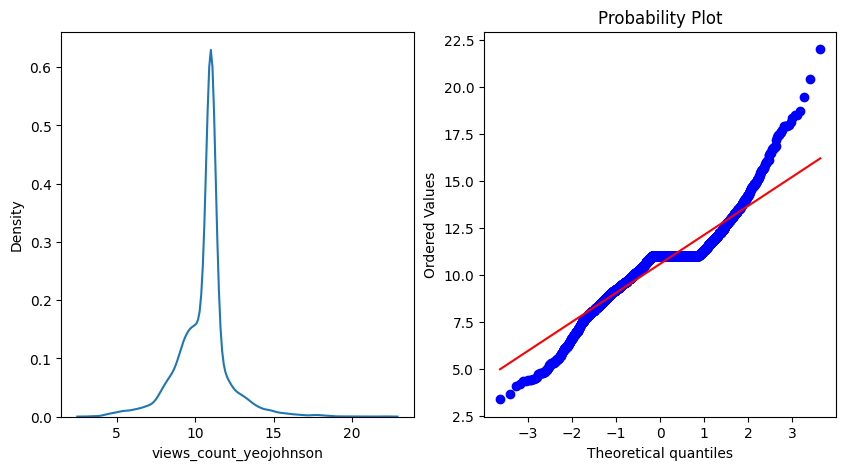

In [ ]:
from scipy.stats import yeojohnson
df2['views_count_yeojohnson'],lymbda=yeojohnson(df2['views_count'],lmbda=None)
normality(df2,'views_count_yeojohnson')

In [ ]:
print(lymbda)

0.047454707989310466


In [ ]:
df2=df2.drop(['views_count_yeojohnson','views_count_Boxcox'],axis=1)

In [ ]:
df2

,platform,likes_count,shares_count,comments_count,views_count,hour
3025,TikTok,799.0,48.0,320.0,6979.000000,0.0
3026,TikTok,409.0,72.0,20.0,4634.000000,13.0
3027,TikTok,163.0,18.0,29.0,1718.000000,18.0
3028,TikTok,1948.0,74.0,994.0,14200.000000,20.0
3029,TikTok,2950.0,570.0,650.0,32800.000000,13.0
...,...,...,...,...,...,...
8020,Facebook,50.0,68.0,126.0,7038.887279,5.0
8021,Facebook,2001.0,1078.0,2266.0,7038.887279,4.0
8022,Facebook,699.0,46.0,737.0,7038.887279,6.0
8023,Facebook,264.0,207.0,414.0,7038.887279,5.0


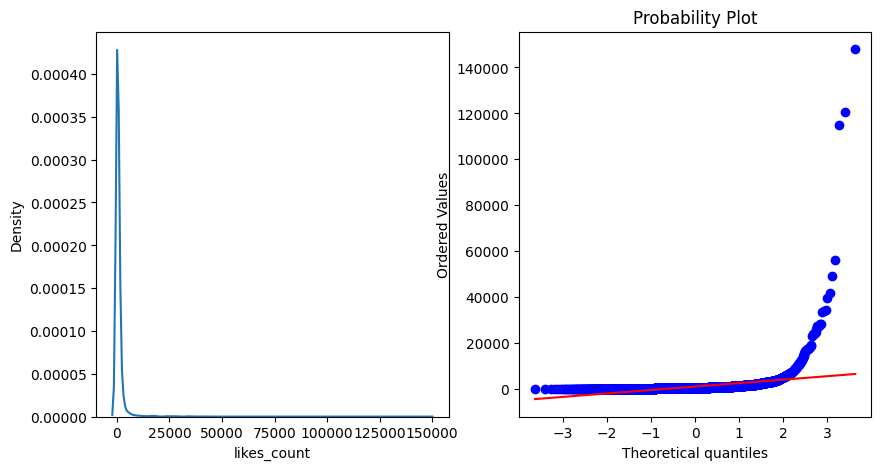

In [ ]:
normality(df2,'likes_count')

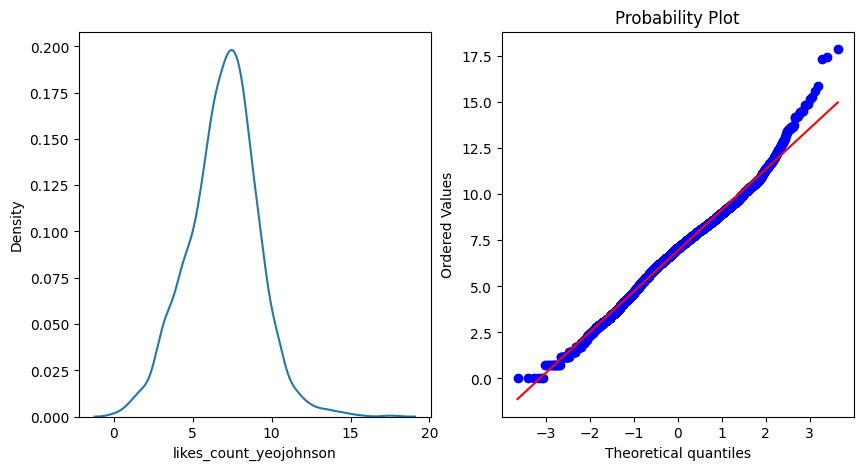

In [ ]:
df2['likes_count_yeojohnson'],lymbda=yeojohnson(df2['likes_count'],lmbda=None)
normality(df2,'likes_count_yeojohnson')

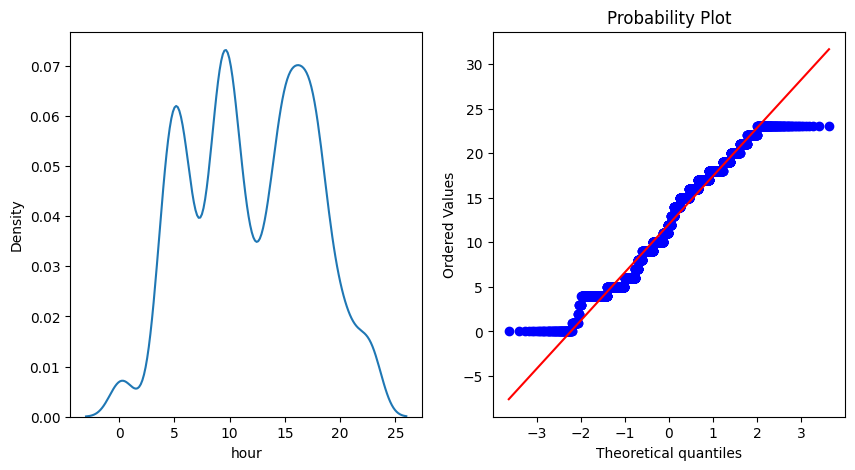

In [ ]:
normality(df2,'hour')

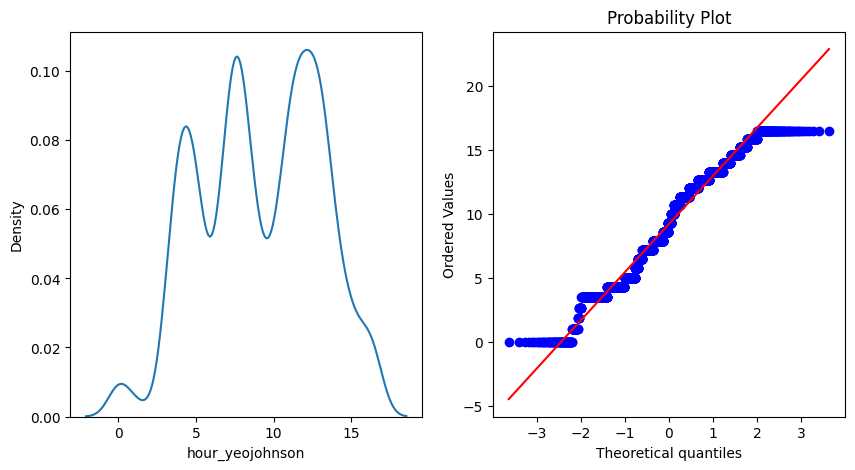

In [ ]:
df2['hour_yeojohnson'],lymbda=yeojohnson(df2['hour'],lmbda=None)
normality(df2,'hour_yeojohnson')

In [ ]:
print(lymbda)

0.8533018841538768


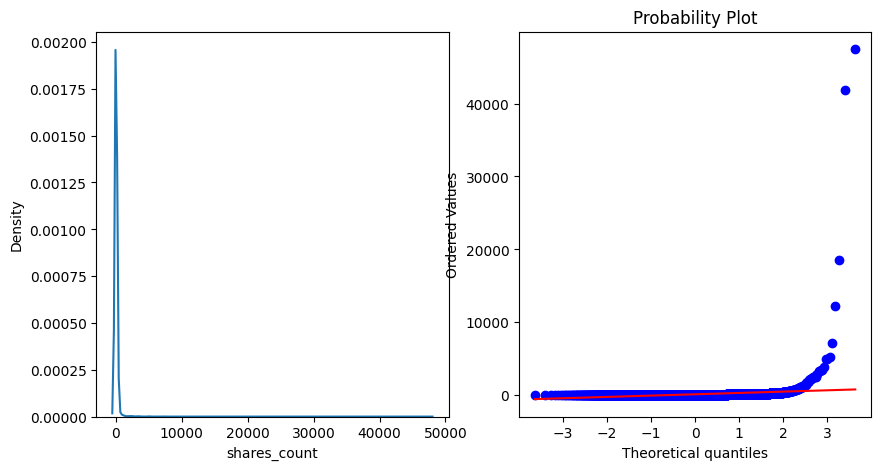

In [ ]:
normality(df2,'shares_count')

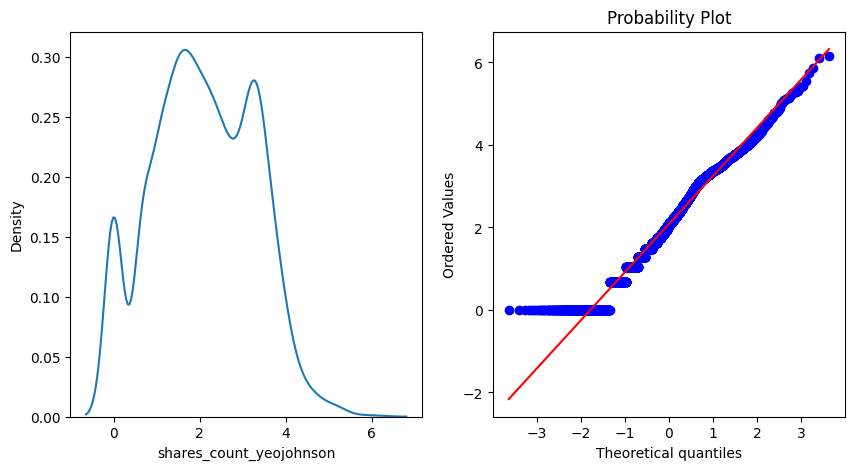

In [ ]:
df2['shares_count_yeojohnson'],lymbda=yeojohnson(df2['shares_count'],lmbda=None)
normality(df2,'shares_count_yeojohnson')

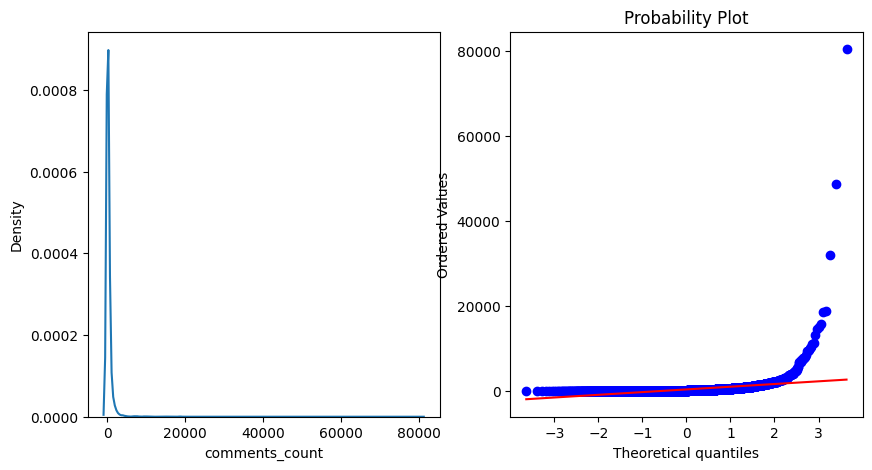

In [ ]:
normality(df2,'comments_count')

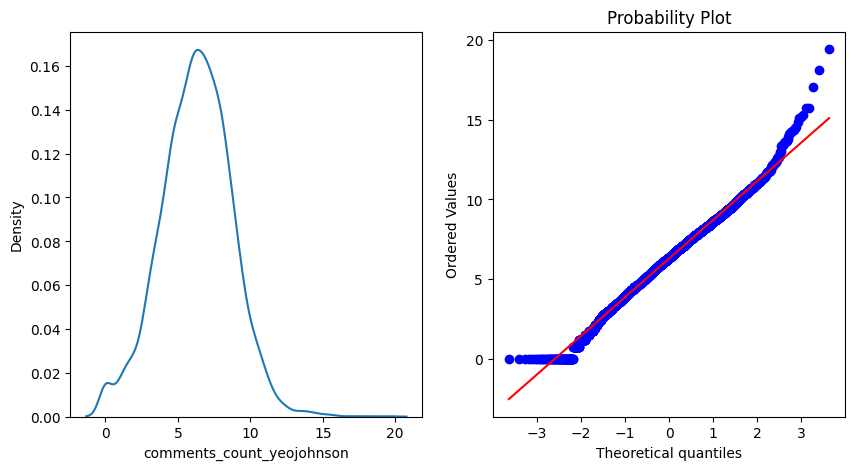

In [ ]:
df2['comments_count_yeojohnson'],lymbda=yeojohnson(df2['comments_count'],lmbda=None)
normality(df2,'comments_count_yeojohnson')

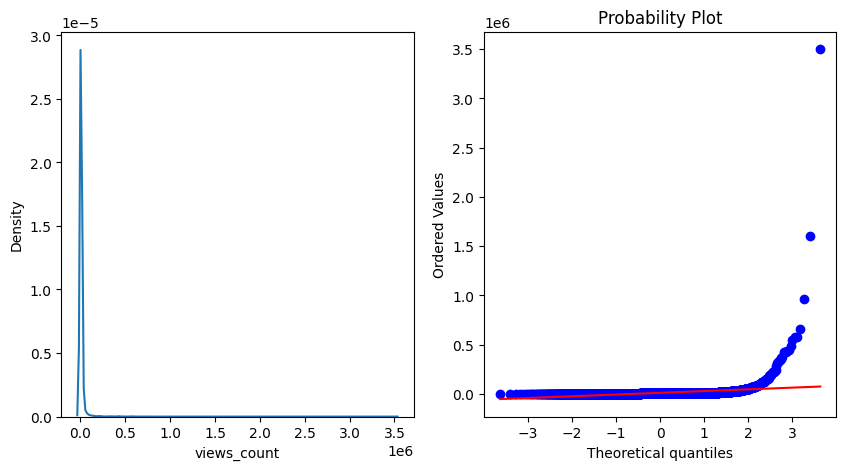

In [ ]:
normality(df2,'views_count')

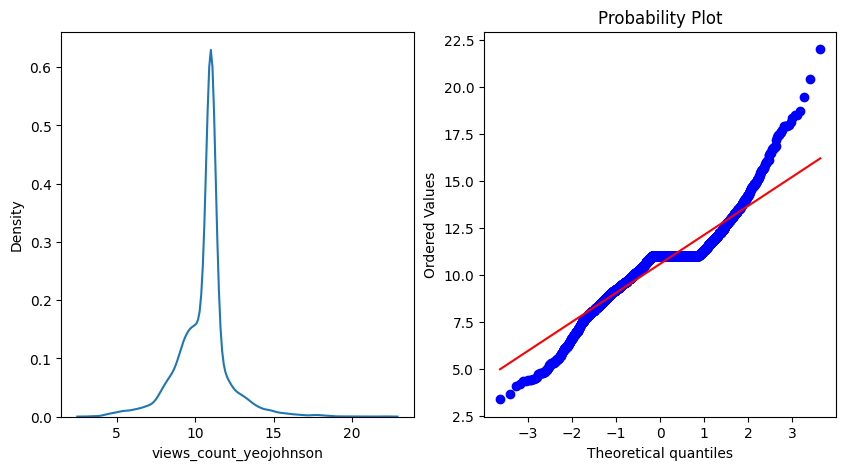

In [ ]:
df2['views_count_yeojohnson'],lymbda=yeojohnson(df2['views_count'],lmbda=None)
normality(df2,'views_count_yeojohnson')

In [ ]:
df2

,likes_count,shares_count,comments_count,views_count,hour,likes_count_yeojohnson,hour_yeojohnson,shares_count_yeojohnson,comments_count_yeojohnson,views_count_yeojohnson
3025,799.0,48.0,320.0,6979.000000,0.0,8.348029,0.000000,3.133094,7.539415,10.999548
3026,409.0,72.0,20.0,4634.000000,13.0,7.343069,9.968218,3.381351,3.495897,10.382444
3027,163.0,18.0,29.0,1718.000000,18.0,6.033740,13.284482,2.495027,3.970800,8.936154
3028,1948.0,74.0,994.0,14200.000000,20.0,9.755527,14.573330,3.397772,9.526414,12.098979
3029,2950.0,570.0,650.0,32800.000000,13.0,10.439203,9.968218,4.495109,8.757809,13.443302
...,...,...,...,...,...,...,...,...,...,...
8020,50.0,68.0,126.0,7038.887279,5.0,4.472543,4.234321,3.346948,6.053287,11.012553
8021,2001.0,1078.0,2266.0,7038.887279,4.0,9.799198,3.455404,4.789320,11.103594,11.012553
8022,699.0,46.0,737.0,7038.887279,6.0,8.143816,4.994331,3.106474,8.982057,11.012553
8023,264.0,207.0,414.0,7038.887279,5.0,6.709830,4.234321,3.981391,7.973165,11.012553


In [ ]:
df.columns

Index(['likes_count', 'shares_count', 'comments_count', 'views_count', 'hour',
       'likes_count_yeojohnson', 'hour_yeojohnson', 'shares_count_yeojohnson',
       'comments_count_yeojohnson'],
      dtype='object')

Цільову змінну не потрібно стандартизувати мін максним або іншим перетворенням

In [ ]:
df2=df2.drop(['likes_count', 'shares_count', 'comments_count', 'views_count', 'hour'],axis=1)
from sklearn.preprocessing import MinMaxScaler
scale= MinMaxScaler()
df1 = scale.fit_transform(df2)
df=pd.DataFrame(df1, columns=df2.columns)
df

,likes_count_yeojohnson,hour_yeojohnson,shares_count_yeojohnson,comments_count_yeojohnson,views_count_yeojohnson
0,0.467076,0.000000,0.509077,0.387753,0.409046
1,0.410848,0.605103,0.549415,0.179795,0.375914
2,0.337590,0.806411,0.405401,0.204219,0.298264
3,0.545826,0.884648,0.552083,0.489945,0.468074
4,0.584078,0.605103,0.730382,0.450415,0.540250
...,...,...,...,...,...
4995,0.250241,0.257037,0.543825,0.311321,0.409745
4996,0.548269,0.209754,0.778187,0.571060,0.409745
4997,0.455650,0.303172,0.504752,0.461949,0.409745
4998,0.375418,0.257037,0.646911,0.410061,0.409745


In [ ]:
df.columns

Index(['likes_count_yeojohnson', 'hour_yeojohnson', 'shares_count_yeojohnson',
       'comments_count_yeojohnson', 'views_count_yeojohnson'],
      dtype='object')

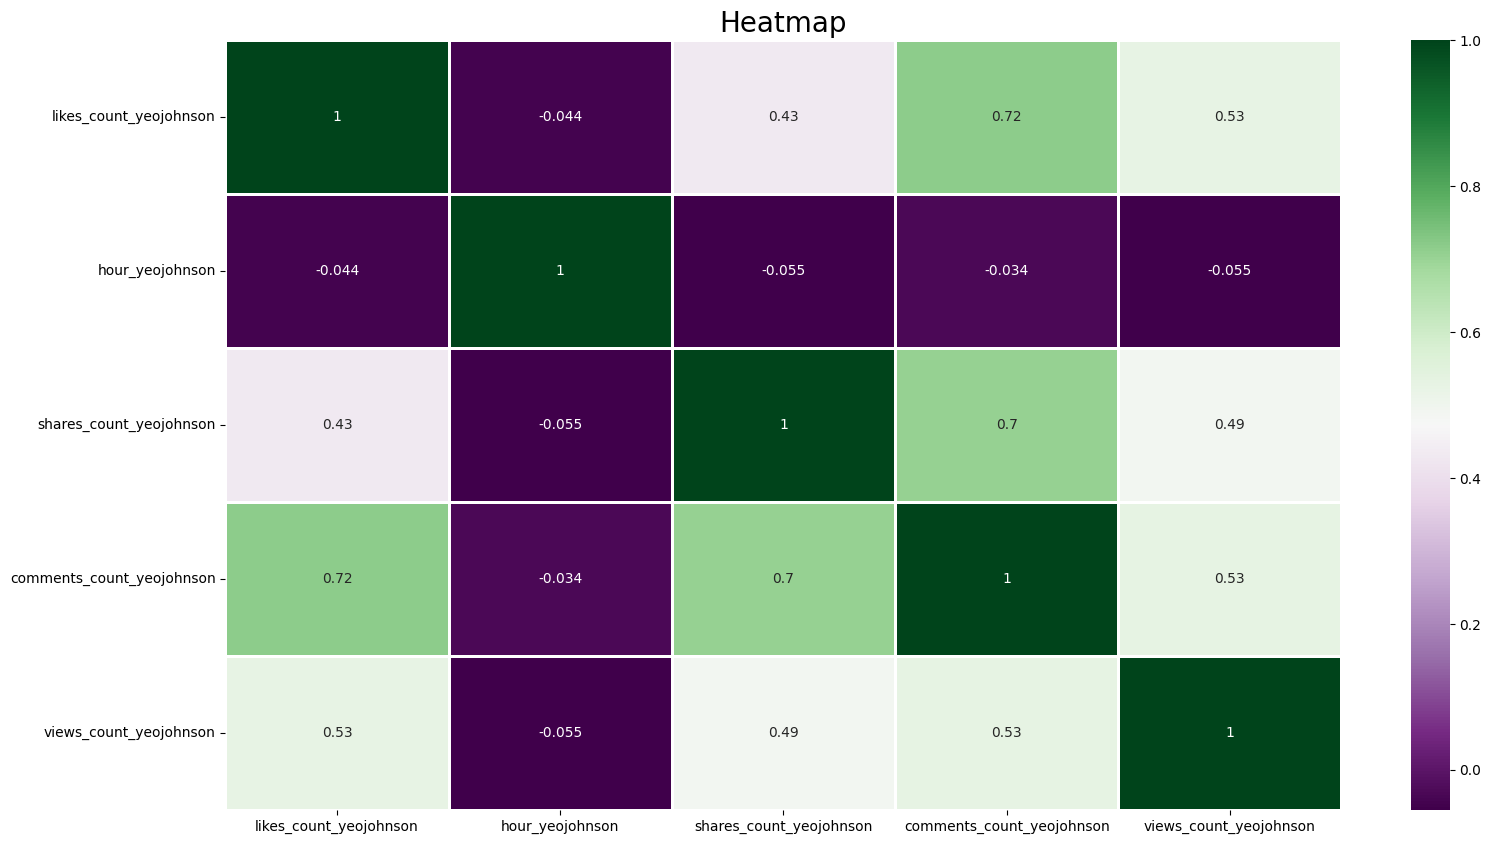

In [ ]:
import seaborn as sns
plt.rcParams['figure.figsize'] = (18, 10)
color = plt.get_cmap('PRGn')   # default color
color.set_bad('lightblue')
sns.heatmap(df[[ 'likes_count_yeojohnson', 'hour_yeojohnson', 'shares_count_yeojohnson',
       'comments_count_yeojohnson', 'views_count_yeojohnson']].corr(), annot = True, cmap=color, linewidths=.8)
plt.title('Heatmap', fontsize = 20)
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

З переглядами найбільше корелюють кількість лайків поширень та коментарів

In [ ]:
y = df2['views_count_yeojohnson']
x = df[['likes_count_yeojohnson']]
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=0)
lm = LinearRegression()
lm.fit(x_train, y_train)
result = lm.predict(x_test)
print('R2 score : ', metrics.r2_score(y_test, result))
#display adjusted R-squared
print('adjusted R2 score : ',1 - (1-metrics.r2_score(y_test, result))*(len(x)-1)/(len(x)-x.shape[1]))
print('MSE: ', metrics.mean_squared_error(y_test,result))
print('MAPE: ', metrics.mean_absolute_percentage_error(y_test,result)*100)

In [ ]:
y = df2['views_count_yeojohnson']
x = df[['likes_count_yeojohnson', 'hour_yeojohnson', 'shares_count_yeojohnson',
       'comments_count_yeojohnson']]
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=0)
lm = LinearRegression()
lm.fit(x_train, y_train)
result = lm.predict(x_test)
print('R2 score : ', metrics.r2_score(y_test, result))
#display adjusted R-squared
print('adjusted R2 score : ',1 - (1-metrics.r2_score(y_test, result))*(len(x)-1)/(len(x)-x.shape[1]))
print('MSE: ', metrics.mean_squared_error(y_test,result))
print('MAPE: ', metrics.mean_absolute_percentage_error(y_test,result)*100)

R2 score :  0.3255831857252267
adjusted R2 score :  0.32517821165740757
MSE:  1.6479060701413115
MAPE:  9.718324315002523


Пояснювальна дисперсія 32%, підігнаність моделі 9%, скоріше за все вона перенавчається (якщо MAPE до 10% то модель підігнано добре)

Спробуємо зменшити кількість ознак

In [ ]:
y = df2['views_count_yeojohnson']
x = df[['shares_count_yeojohnson','likes_count_yeojohnson']]
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=0)
lm = LinearRegression()
lm.fit(x_train, y_train)
result = lm.predict(x_test)
print('R2 score : ', metrics.r2_score(y_test, result))
#display adjusted R-squared
print('adjusted R2 score : ',1 - (1-metrics.r2_score(y_test, result))*(len(x)-1)/(len(x)-x.shape[1]))
print('MSE: ', metrics.mean_squared_error(y_test,result))
print('MAPE: ', metrics.mean_absolute_percentage_error(y_test,result)*100)

R2 score :  0.3280126395156774
adjusted R2 score :  0.32787818826307946
MSE:  1.6419698129726397
MAPE:  9.753982081371914


In [ ]:
y = df2['views_count_yeojohnson']
x = df[['shares_count_yeojohnson','comments_count_yeojohnson', 'hour_yeojohnson']]
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=0)
lm = LinearRegression()
lm.fit(x_train, y_train)
result = lm.predict(x_test)
print('R2 score : ', metrics.r2_score(y_test, result))
#display adjusted R-squared
print('adjusted R2 score : ',1 - (1-metrics.r2_score(y_test, result))*(len(x)-1)/(len(x)-x.shape[1]))
print('MSE: ', metrics.mean_squared_error(y_test,result))
print('MAPE: ', metrics.mean_absolute_percentage_error(y_test,result)*100)

R2 score :  0.2716055937901659
adjusted R2 score :  0.27131406110807277
MSE:  1.7797978016620457
MAPE:  9.778204544434448


Оскільки точність зменшилась а додавання стовпця із годинами не сильно підвищею точність то залишаємо ітльки два входи це поширення та лайки

In [ ]:
y = df2['views_count_yeojohnson']
x = df[['shares_count_yeojohnson','likes_count_yeojohnson']]
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=0)
lm = LinearRegression()
lm.fit(x_train, y_train)
result = lm.predict(x_test)
print('R2 score : ', metrics.r2_score(y_test, result))
#display adjusted R-squared
print('adjusted R2 score : ',1 - (1-metrics.r2_score(y_test, result))*(len(x)-1)/(len(x)-x.shape[1]))
print('MSE: ', metrics.mean_squared_error(y_test,result))
print('MAPE: ', metrics.mean_absolute_percentage_error(y_test,result)*100)

R2 score :  0.3280126395156774
adjusted R2 score :  0.32787818826307946
MSE:  1.6419698129726397
MAPE:  9.753982081371914


Отже, покращення індексів якості моделі показало (в т.ч. скоригованого коефіцієнта детермінації), що є доцільним додавання інших предикторних змінних до моделі. Найоптимальнішим варіантом є попередня модель. Точність моделі R2 не дуже висока (32%) скоріше за все така точність оскільки природа даних у датасеті не є лінійною.

Text(0.5, 1.0, 'Модель MLR')

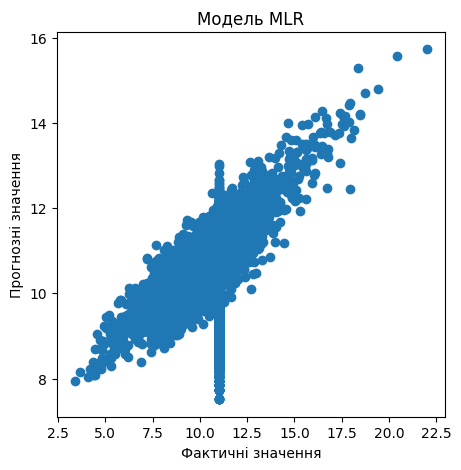

In [ ]:
result = lm.predict(x)
plt.rcParams['figure.figsize'] = (5, 5)
plt.scatter(y, result)
plt.xlabel("Фактичні значення")
plt.ylabel("Прогнозні значення")
plt.title('Модель MLR')

In [ ]:
print("shares_count_yeojohnson : {0} , likes_count_yeojohnson: {1}".format(lm.coef_[0], lm.coef_[1]))
print("Intercept : ",lm.intercept_)

shares_count_yeojohnson : 2.802472422241231 , likes_count_yeojohnson: 5.412250733442469
Intercept :  7.514574725580981


In [ ]:
x_test

,shares_count_yeojohnson,likes_count_yeojohnson
398,0.208103,0.482472
3833,0.108224,0.219325
4836,0.509077,0.348654
4572,0.490429,0.498244
636,0.283092,0.495990
...,...,...
4554,0.460393,0.381537
4807,0.497863,0.376915
1073,0.000000,0.429594
2906,0.000000,0.156001


In [ ]:
import numpy as np

x1=[0.509077,0.348654]
y_pred = np.dot(lm.coef_,x1)+lm.intercept_
print(y_pred)


10.828251846095931
